# 09_06 The Randomness Inside Neural Networks

**Learning objectives**
- Derive **Xavier/Glorot** and **He** weight initialisation from the requirement that the **variance of the signal** neither vanishes nor explodes with depth, and check it by simulation.
- Describe **dropout** as multiplication by Bernoulli masks, compute its mean and variance, and use **Monte-Carlo dropout** and **ensembles** to obtain predictive uncertainty.
- Explain **label smoothing** as a change of the target distribution and its effect on logits and calibration; quantify the **noise of minibatch SGD** ($\propto1/B$) and the **seed-to-seed variability** of training.
- Build and train a small neural network from scratch (NumPy forward and backward pass, Adam).

**Prerequisites:** [09_01 Losses as likelihoods](09_01_losses_as_likelihoods.ipynb), [08_01 Entropy and cross-entropy](../../module_08_information/notebooks/08_01_entropy_cross_entropy.ipynb), [05_01 Law of large numbers](../../module_05_sampling/notebooks/05_01_law_of_large_numbers.ipynb), [01_01 Bernoulli](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
For independent $a,b$: $\mathrm{Var}(ab)=E[a^2]E[b^2]-E[a]^2E[b]^2$, and $\mathrm{Var}(\sum_ia_i)=\sum\mathrm{Var}(a_i)$. A Bernoulli($q$) variable has mean $q$ and variance $q(1-q)$. The variance of a sample mean of $B$ i.i.d. terms is $\sigma^2/B$ (05_01). Cross-entropy and softmax outputs are as in 08_01 and 09_01.

## 3. Intuition and story
A neural network is a stack of random-looking linear maps. If the first weights are too small the signal shrinks layer after layer until the output no longer depends on the input; if they are too large it explodes. Choosing the **scale of the random initial weights** is therefore a statistical problem with a clean answer: keep the variance of each layer's activations about constant. Randomness then reappears *during* training in four places: **dropout** (random masks), **minibatch sampling** (noisy gradients), **label smoothing** (a softened target distribution) and the **random seed** itself. Treated as distributions, each of them has a mean and a variance we can compute, and they can be turned into an uncertainty estimate.

## 4. Formal definitions

A dense layer maps $h_{l-1}\in\mathbb R^{n_{\text{in}}}$ to $a_l=W_lh_{l-1}+b_l$, $h_l=\phi(a_l)$, with $W_{ij}$ i.i.d. of variance $\sigma_w^2$.

| Scheme | $\mathrm{Var}(W_{ij})$ | Designed for |
|---|---|---|
| **Xavier / Glorot** (normal) | $\dfrac{2}{n_{\text{in}}+n_{\text{out}}}$ (or $\dfrac1{n_{\text{in}}}$) | tanh, sigmoid, linear |
| **He / Kaiming** | $\dfrac{2}{n_{\text{in}}}$ | ReLU |
| **Dropout** (rate $p$, inverted) | $h\mapsto h\odot m/(1-p)$, $m_i\sim\mathrm{Bernoulli}(1-p)$ | regularisation, MC uncertainty |
| **MC dropout** | average of $T$ stochastic forward passes with dropout kept on | predictive mean and std |
| **Label smoothing** ($\varepsilon$, $K$ classes) | target $y^{\mathrm{ls}}=(1-\varepsilon)y+\varepsilon/K$ | calibration, less over-confidence |
| **Minibatch gradient** | $\hat g_B=\frac1B\sum_{i\in\mathcal B}g_i$ | $\mathrm{Var}(\hat g_B)=\Sigma_g/B$ (sampling without replacement times $\frac{N-B}{N-1}$) |

## 5. Derivations

### 5.1 Forward signal: variance of a layer
If the inputs $h_{l-1,j}$ are independent with $E[h]=0$ and $E[h^2]=q_{l-1}$, then for $a_i=\sum_jW_{ij}h_j$: $\ \mathrm{Var}(a_i)=n_{\text{in}}\sigma_w^2\,q_{l-1}$. For a linear (or approximately linear) layer $q_l=n_{\text{in}}\sigma_w^2q_{l-1}$, so after $L$ layers $q_L=(n_{\text{in}}\sigma_w^2)^Lq_0$: the signal shrinks or grows **geometrically** unless $n_{\text{in}}\sigma_w^2=1$, i.e. $\sigma_w^2=1/n_{\text{in}}$ (LeCun / Xavier for tanh near zero). **In plain words.** Each layer multiplies the signal's variance by (width x weight variance); anything other than 1 compounds exponentially with depth.

### 5.2 ReLU halves the variance, so He doubles the weights
For a ReLU, $h=\max(0,a)$ with symmetric $a$ gives $E[h^2]=\tfrac12\mathrm{Var}(a)$. Then $q_l=\tfrac12n_{\text{in}}\sigma_w^2q_{l-1}$, stable iff $\sigma_w^2=2/n_{\text{in}}$ (He). **In plain words.** A ReLU throws away the negative half of the signal; to keep the variance, the weights must be larger by a factor $\sqrt2$.

### 5.3 Backward signal and the Xavier compromise
Gradients flow backwards through $W^\top$, so the same argument gives a back-propagated variance multiplier $n_{\text{out}}\sigma_w^2$. Requiring both forward and backward stability gives $\sigma_w^2=2/(n_{\text{in}}+n_{\text{out}})$ (Glorot). **In plain words.** When a layer changes the width, you cannot keep both the forward and the backward signal exactly stable; the harmonic compromise does about as well as possible for both.

### 5.4 Dropout is multiplicative noise with known moments
With inverted dropout the mask is $m_i/(1-p)$ with $m_i\sim\mathrm{Bernoulli}(1-p)$. Then $E[h\,m/(1-p)]=h$ (the expected activation is unchanged) and $\mathrm{Var}[h\,m/(1-p)]=h^2\,\dfrac p{1-p}$. For a sum over $n$ units the extra output variance is $\dfrac p{1-p}\sum_jw_j^2h_j^2$. **In plain words.** Dropout leaves the average prediction alone but adds noise proportional to the size of each activation; the odds $p/(1-p)$ set how noisy the network becomes.

### 5.5 MC dropout and the predictive variance
Averaging $T$ stochastic passes gives the predictive mean $\bar y=\frac1T\sum y_t$ and the sample variance $\frac1{T-1}\sum(y_t-\bar y)^2$. Interpreted as approximate Bayesian inference (Gal and Ghahramani) the total variance is (variance of the stochastic outputs) + (observation noise $\sigma^2$). **In plain words.** If many "thinned" copies of the network disagree about an input, the network is unsure there; where they agree, the input resembles the training data. The disagreement is only a *lower bound* on the true uncertainty.

### 5.6 Label smoothing
With smoothing $\varepsilon$ on $K$ classes the target for the true class is $1-\varepsilon+\varepsilon/K$ and for each other class $\varepsilon/K$. The cross-entropy is minimised when the predicted probabilities equal this target; for $K=2$ the optimal logit gap is $\ln\frac{1-\varepsilon/2}{\varepsilon/2}$ (2.94 for $\varepsilon=0.1$). Without smoothing the optimum is at infinite logits (separable data). **In plain words.** A hard 0/1 target rewards ever larger logits; a softened target puts the optimum at a finite, moderate confidence.

### 5.7 Minibatch noise
The full gradient is $g=\frac1N\sum g_i$. A random minibatch gives $\hat g_B$ with $E\hat g_B=g$ and covariance $\Sigma_g/B\cdot\frac{N-B}{N-1}$. **In plain words.** Quadrupling the batch size halves the standard deviation of the gradient noise; the noise is what lets SGD jump out of sharp minima, and it has to be traded against cost per step.

## 6. Properties and relationships
- **Exponential in depth:** a 10 % error in the weight scale (1.1x) after 50 layers means a factor $1.1^{100}\approx10^4$ in the variance: initialisation matters most for deep networks without normalisation.
- **Normalisation layers** (batch norm, layer norm) re-impose unit variance and make training less sensitive to the initial scale, at the cost of other assumptions.
- **Residual connections** add the identity, which keeps the variance from collapsing.
- **Dropout at test time:** switched off for the point prediction (inverted scaling keeps the mean), switched on for MC uncertainty.
- **Weight decay** is a Gaussian prior on the weights (09_12); **early stopping** and **data augmentation** are further regularisers.
- **Link to ML and AI:** every deep network; the initialisation recipes of PyTorch and TensorFlow, dropout in transformers, MC dropout and **deep ensembles** for uncertainty, label smoothing in image and translation models, and the batch-size/learning-rate scaling rules of large-scale training.

## 7. A small neural network from scratch

A fully connected network with tanh hidden layers, manual backward pass, optional inverted dropout and the Adam optimiser. Gradients are checked against finite differences.

In [2]:
class MLP:
    def __init__(self, sizes, init="he", seed=0, drop=0.0):
        g = np.random.default_rng(seed); self.sizes = sizes; self.drop = drop; self.W = []; self.b = []
        for i, o in zip(sizes[:-1], sizes[1:]):
            var = {"he": 2 / i, "xavier": 2 / (i + o), "lecun": 1 / i}[init]; self.W.append(g.normal(0, np.sqrt(var), (i, o))); self.b.append(np.zeros(o))
        self.m = [np.zeros_like(p) for p in self.W + self.b]; self.v = [np.zeros_like(p) for p in self.W + self.b]; self.t = 0
    def forward(self, X, train=False, rng=None):
        h = X; self.inp = []; self.th = []; self.mk = []
        for l in range(len(self.W)):
            self.inp.append(h); a = h @ self.W[l] + self.b[l]
            if l == len(self.W) - 1: return a
            t = np.tanh(a); self.th.append(t); m = None
            if train and self.drop > 0: m = (rng.random(t.shape) > self.drop) / (1 - self.drop); h = t * m
            else: h = t
            self.mk.append(m)
    def backward(self, dout):
        L = len(self.W); gW = [None] * L; gb = [None] * L; d = dout
        for l in reversed(range(L)):
            gW[l] = self.inp[l].T @ d; gb[l] = d.sum(axis=0)
            if l > 0:
                d_in = d @ self.W[l].T; m = self.mk[l - 1]
                if m is not None: d_in = d_in * m
                d = d_in * (1 - self.th[l - 1] ** 2)
        return gW + gb
    def adam(self, grads, lr=0.01, b1=0.9, b2=0.999):
        self.t += 1; params = self.W + self.b
        for k, (p, gk) in enumerate(zip(params, grads)): self.m[k] = b1 * self.m[k] + (1 - b1) * gk; self.v[k] = b2 * self.v[k] + (1 - b2) * gk ** 2; p -= lr * (self.m[k] / (1 - b1 ** self.t)) / (np.sqrt(self.v[k] / (1 - b2 ** self.t)) + 1e-8)
def fit_reg(net, X, y, epochs=3000, lr=0.01, seed=0, wd=0.0):
    rng = np.random.default_rng(seed); n = len(X)
    for ep in range(epochs):
        pred = net.forward(X, train=True, rng=rng); gr = net.backward(2 * (pred - y) / n)
        if wd: gr = [gk + (wd * p if k < len(net.W) else 0) for k, (gk, p) in enumerate(zip(gr, net.W + net.b))]
        net.adam(gr, lr)
    return net
# finite-difference gradient check
g = np.random.default_rng(1); Xg = g.normal(size=(8, 3)); yg = g.normal(size=(8, 1)); net = MLP([3, 5, 4, 1], "xavier", seed=2); loss = lambda: np.mean((net.forward(Xg) - yg) ** 2); gr = net.backward(2 * (net.forward(Xg) - yg) / len(Xg)); worst = 0
for k, p in enumerate(net.W + net.b):
    it = np.ndindex(*p.shape); idx = next(it); old = p[idx]; p[idx] = old + 1e-6; lp = loss(); p[idx] = old - 1e-6; lm = loss(); p[idx] = old; worst = max(worst, abs((lp - lm) / 2e-6 - gr[k][idx]))
print("largest gradient error (backprop against finite differences):", worst); assert worst < 1e-6

largest gradient error (backprop against finite differences): 2.4852053748247727e-10


## 8. 2D visuals

### 8.1 Signal strength through 40 layers
The standard deviation of the activations layer by layer for a 40-layer network (width 256, tanh) with three weight scales: half the Xavier scale, the Xavier scale and twice the Xavier scale. Only the middle one keeps the signal alive.

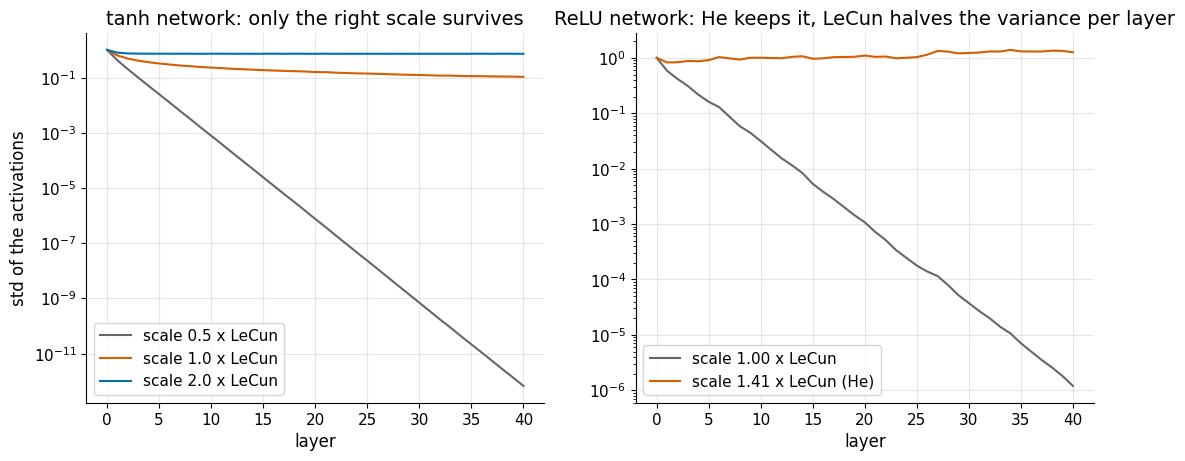

std after 40 layers: tanh 0.5 / 1 / 2 x: {0.5: 0.0, 1.0: 0.1057, 2.0: 0.7266} | ReLU LeCun / He: 0.0 1.257


In [3]:
def propagate(L, width, scale, act, seed=0, n=500):
    g = np.random.default_rng(seed); h = g.normal(size=(n, width)); out = [h.std()]
    for _ in range(L): W = g.normal(0, scale * np.sqrt(1 / width), (width, width)); a = h @ W; h = np.tanh(a) if act == "tanh" else np.maximum(a, 0); out.append(h.std())
    return np.array(out)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); res = {}
for sc, colr in [(0.5, NEUTRAL), (1.0, HIGHLIGHT), (2.0, MAIN)]: s_ = propagate(40, 256, sc, "tanh"); res[sc] = s_; axes[0].semilogy(s_, color=colr, label=f"scale {sc} x LeCun")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("std of the activations"); axes[0].legend(); axes[0].set_title("tanh network: only the right scale survives")
for sc, colr in [(1.0, NEUTRAL), (np.sqrt(2), HIGHLIGHT)]: s_ = propagate(40, 256, sc, "relu"); res[("relu", sc)] = s_; axes[1].semilogy(s_, color=colr, label=f"scale {sc:.2f} x LeCun" + (" (He)" if sc > 1.2 else ""))
axes[1].set_xlabel("layer"); axes[1].legend(); axes[1].set_title("ReLU network: He keeps it, LeCun halves the variance per layer")
plt.show(); print("std after 40 layers: tanh 0.5 / 1 / 2 x:", {k: round(float(v[-1]), 4) for k, v in res.items() if not isinstance(k, tuple)}, "| ReLU LeCun / He:", round(float(res[("relu", 1.0)][-1]), 5), round(float(res[("relu", np.sqrt(2))][-1]), 3))
assert res[0.5][-1] < 1e-3 and res[1.0][-1] > 0.05 and res[("relu", 1.0)][-1] < 1e-3 and 0.3 < res[("relu", np.sqrt(2))][-1] / res[("relu", np.sqrt(2))][0] < 3

### 8.2 What the pre-activations look like
Histograms of the pre-activations at layers 1, 10 and 30 for a tanh network. With too-large weights the units saturate at $\pm1$ (derivative zero: vanishing gradients); with the right scale they stay in the linear range.

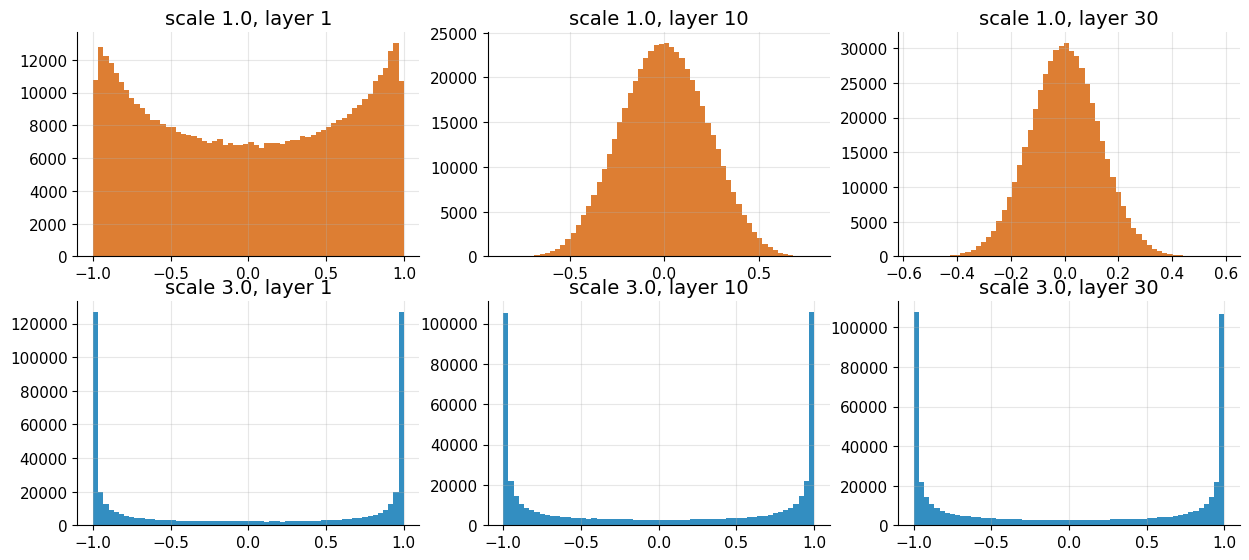

share of saturated units (|h| > 0.99): {(1.0, 0): 0.008, (1.0, 9): 0.0, (1.0, 29): 0.0, (3.0, 0): 0.376, (3.0, 9): 0.288, (3.0, 29): 0.295}


In [4]:
def acts(L, width, scale, seed=0, n=2000):
    g = np.random.default_rng(seed); h = g.normal(size=(n, width)); outs = []
    for l in range(L): a = h @ g.normal(0, scale * np.sqrt(1 / width), (width, width)); h = np.tanh(a); outs.append(h.copy())
    return outs
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4)); sat = {}
for r, sc in enumerate([1.0, 3.0]):
    o = acts(30, 256, sc)
    for c, l in enumerate([0, 9, 29]): axes[r, c].hist(o[l].ravel(), bins=60, color=[HIGHLIGHT, MAIN][r], alpha=0.8); axes[r, c].set_title(f"scale {sc}, layer {l + 1}"); sat[(sc, l)] = np.mean(np.abs(o[l]) > 0.99)
plt.show(); print("share of saturated units (|h| > 0.99):", {k: round(float(v), 3) for k, v in sat.items()}); assert sat[(3.0, 9)] > 0.2 and sat[(1.0, 9)] < 0.01

### 8.3 Dropout: what the masks do
One hidden unit with activation 2 under dropout rate $p=0.3$: the output takes the values 0 or $2/0.7=2.857$; its mean is 2 and its variance $4\,p/(1-p)=1.714$. Right: the output of a layer of 100 units has relative noise $\sqrt{p/((1-p)\,n)}$ on average.

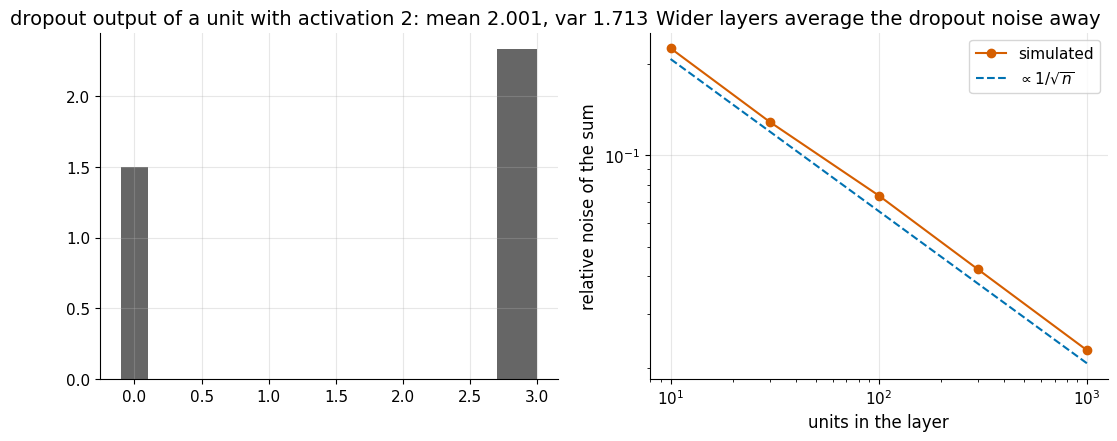

mean 2.0012 (theory 2), variance 1.7130 (theory 1.7143) | slope of the relative noise against n: -0.494 (theory -0.5)


In [5]:
g = np.random.default_rng(3); p = 0.3; mk = (g.random(1_000_000) > p) / (1 - p); out = 2 * mk; fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); axes[0].hist(out, bins=[-0.1, 0.1, 2.7, 3.0], color=NEUTRAL, density=True); axes[0].set_title(f"dropout output of a unit with activation 2: mean {out.mean():.3f}, var {out.var():.3f}")
ns = np.array([10, 30, 100, 300, 1000]); rel = []; hh = np.abs(g.normal(size=2000)) + 0.5
for n_ in ns: hv = np.abs(g.normal(size=n_)) + 0.5; samp = [np.sum(hv * (g.random(n_) > p) / (1 - p)) for _ in range(4000)]; rel.append(np.std(samp) / np.sum(hv))
axes[1].loglog(ns, rel, "o-", color=HIGHLIGHT, label="simulated"); axes[1].loglog(ns, 0.5 * np.sqrt(p / (1 - p) / ns) * 2, "--", color=MAIN, label="$\\propto 1/\\sqrt{n}$"); axes[1].legend(); axes[1].set_xlabel("units in the layer"); axes[1].set_ylabel("relative noise of the sum"); axes[1].set_title("Wider layers average the dropout noise away")
plt.show(); print(f"mean {out.mean():.4f} (theory 2), variance {out.var():.4f} (theory {4 * p / (1 - p):.4f}) | slope of the relative noise against n: {np.polyfit(np.log(ns), np.log(rel), 1)[0]:.3f} (theory -0.5)"); assert abs(out.mean() - 2) < 0.01 and abs(out.var() - 4 * p / (1 - p)) < 0.02 and abs(np.polyfit(np.log(ns), np.log(rel), 1)[0] + 0.5) < 0.08

## 9. 3D visuals

### 9.1 Static: the signal variance after $L$ layers
$\log_{10}$ of the variance after $L$ layers as a function of the depth and the weight-scale factor $s$ (variance multiplier $s^2$ per layer for a linear network): a plane through the origin along $s=1$ that tilts steeply up or down.

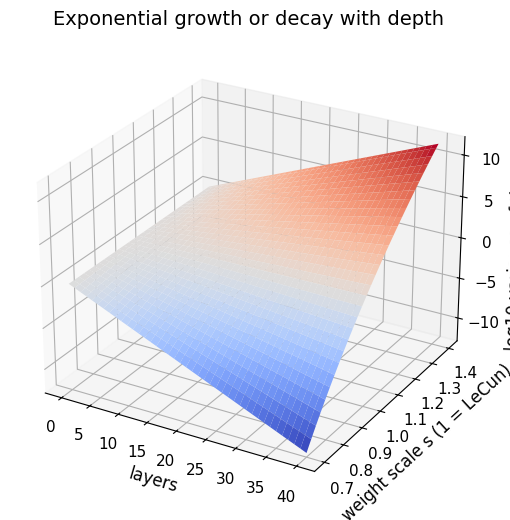

after 50 layers a scale error of 10% gives the variance factor 10^(100 log10 1.1) = 1.38e+04 and 0.9 gives 2.66e-05


In [6]:
Ls = np.arange(0, 41); ss = np.linspace(0.7, 1.4, 60); LL, SS = np.meshgrid(Ls, ss); V = LL * 2 * np.log10(SS)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(LL, SS, V, cmap="coolwarm", edgecolor="none"); ax.set_xlabel("layers"); ax.set_ylabel("weight scale s (1 = LeCun)"); ax.set_zlabel("log10 variance of the signal"); ax.set_title("Exponential growth or decay with depth"); ax.view_init(elev=26, azim=-60)
plt.show(); print("after 50 layers a scale error of 10% gives the variance factor 10^(100 log10 1.1) =", f"{1.1 ** 100:.3g}", "and 0.9 gives", f"{0.9 ** 100:.3g}"); assert abs(V[np.argmin(np.abs(ss - 1)), -1]) < 0.5 and V[-1, -1] > 5 and V[0, -1] < -5

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=Ls, y=ss, z=V, colorscale="RdBu_r")); fig.update_layout(title="log10 variance after L layers", width=760, height=560, scene=dict(xaxis_title="layers", yaxis_title="scale", zaxis_title="log10 var")); fig.show()

### 9.3 Static: a network's function and its MC-dropout uncertainty
A network with dropout 0.2 is trained on 40 noisy points of $\sin(2x)$ in $[-2,2]$; the surface shows the predictive standard deviation over (input $x$, dropout rate used at test time). It grows with the dropout rate, but, as the plot shows, it hardly grows when we move **outside** the data range: MC dropout measures how much the thinned networks disagree, not how far an input is from the training data.

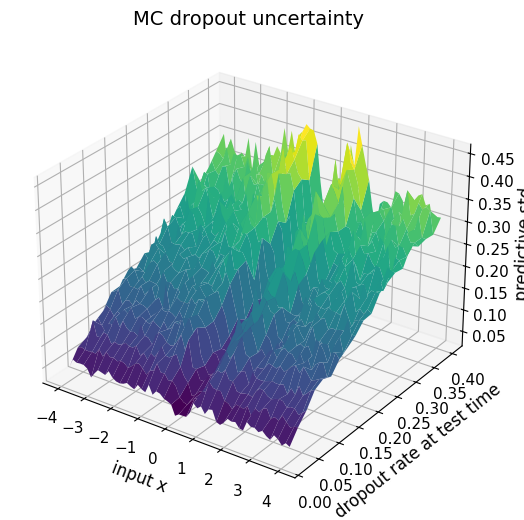

mean predictive std inside the data range 0.2124, outside (|x| > 3) 0.2114; at dropout 0.02 vs 0.4: 0.0564 vs 0.3354


In [8]:
g = np.random.default_rng(4); xtr = g.uniform(-2, 2, 40)[:, None]; ytr = np.sin(2 * xtr) + 0.15 * g.normal(size=(40, 1)); net = fit_reg(MLP([1, 64, 64, 1], "xavier", seed=5, drop=0.2), xtr, ytr, epochs=2500, lr=0.01, seed=6)
xs = np.linspace(-4, 4, 60)[:, None]; rates = np.linspace(0.02, 0.4, 20); SD = np.zeros((len(rates), len(xs))); rng = np.random.default_rng(7)
for i, r in enumerate(rates):
    net.drop = r; SD[i] = np.std([net.forward(xs, train=True, rng=rng)[:, 0] for _ in range(100)], axis=0)
net.drop = 0.2; XX, RR = np.meshgrid(xs[:, 0], rates); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(XX, RR, SD, cmap="viridis", edgecolor="none"); ax.set_xlabel("input x"); ax.set_ylabel("dropout rate at test time"); ax.set_zlabel("predictive std"); ax.set_title("MC dropout uncertainty"); ax.view_init(elev=28, azim=-55)
plt.show(); inside = SD[10][(np.abs(xs[:, 0]) < 1.5)].mean(); outside = SD[10][(np.abs(xs[:, 0]) > 3)].mean(); print(f"mean predictive std inside the data range {inside:.4f}, outside (|x| > 3) {outside:.4f}; at dropout 0.02 vs 0.4: {SD[0].mean():.4f} vs {SD[-1].mean():.4f}"); assert abs(outside - inside) < 0.5 * inside and SD[-1].mean() > 3 * SD[0].mean()

## 10. Simulation vs theory

### 10.1 Variance recursion with wide layers
Compare the simulated variance of the activations after $L$ layers with the recursion $q_L=(n\sigma_w^2/c)^Lq_0$ for a linear network ($c=1$) and for ReLU ($c=2$), width 512, for three scales.

In [9]:
g = np.random.default_rng(8); width = 512; rows = []
for act in ("linear", "relu"):
    for sc in (0.9, 1.0, 1.1):
        h = g.normal(size=(300, width)); q0 = np.mean(h ** 2)
        for _ in range(10): W = g.normal(0, sc * np.sqrt((1 if act == "linear" else 2) / width), (width, width)); a_ = h @ W; h = a_ if act == "linear" else np.maximum(a_, 0)
        rows.append((act, sc, np.mean(h ** 2) / q0, sc ** 20))
tb = pd.DataFrame(rows, columns=["layer type", "scale (1 = LeCun or He)", "simulated variance ratio after 10 layers", "theory s^20"]); print(tb.round(3).to_string(index=False)); assert all(abs(np.log(r[2] / r[3])) < 0.35 for r in rows)

layer type  scale (1 = LeCun or He)  simulated variance ratio after 10 layers  theory s^20
    linear                      0.9                                     0.119        0.122
    linear                      1.0                                     0.989        1.000
    linear                      1.1                                     6.470        6.727
      relu                      0.9                                     0.162        0.122
      relu                      1.0                                     0.930        1.000
      relu                      1.1                                     7.265        6.727


### 10.2 Minibatch gradient noise is $\sigma/\sqrt B$
For linear regression with $N=5{,}000$ points the standard deviation of one coordinate of the minibatch gradient for batch sizes 1 to 512 follows $\sigma_g\sqrt{(N-B)/((N-1)B)}$.

In [10]:
g = np.random.default_rng(9); N = 5000; Xr = g.normal(size=(N, 3)); yr = Xr @ [1.0, -2.0, 0.5] + g.normal(size=N); w0 = np.zeros(3); gi = -2 * (yr - Xr @ w0)[:, None] * Xr; gfull = gi.mean(axis=0); sg = gi[:, 0].std(); rows = []
for B in (1, 4, 16, 64, 256, 1024): gb = np.array([gi[g.choice(N, B, replace=False), 0].mean() for _ in range(3000)]); rows.append((B, gb.std(), sg * np.sqrt((N - B) / ((N - 1) * B)), gb.mean()))
tb = pd.DataFrame(rows, columns=["batch size", "SD of the minibatch gradient", "theory", "mean"]); print(tb.round(4).to_string(index=False), "| full gradient (coordinate 1):", round(float(gfull[0]), 4)); assert all(abs(r[1] / r[2] - 1) < 0.06 for r in rows) and all(abs(r[3] - gfull[0]) < 4 * r[2] / np.sqrt(3000) + 1e-3 for r in rows)

 batch size  SD of the minibatch gradient  theory    mean
          1                        5.3544  5.4037 -1.9796
          4                        2.6841  2.7010 -2.0118
         16                        1.3543  1.3489 -1.9857
         64                        0.6700  0.6712 -1.9985
        256                        0.3271  0.3290 -2.0164
       1024                        0.1530  0.1506 -2.0211 | full gradient (coordinate 1): -2.0213


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("He normal: rng.normal(0, np.sqrt(2 / fan_in)) | Xavier normal: np.sqrt(2 / (fan_in + fan_out)) | Xavier uniform: limit = np.sqrt(6 / (fan_in + fan_out))")
print("inverted dropout: mask = (rng.random(h.shape) > p) / (1 - p); h * mask | MC dropout: np.mean / np.std over T stochastic passes with dropout on")
print("label smoothing: y_ls = (1 - eps) * onehot + eps / K | minibatch noise: sigma / sqrt(B) | library: torch.nn.init.kaiming_normal_, torch.nn.Dropout, CrossEntropyLoss(label_smoothing=0.1)")
print("Xavier uniform bound for fan_in = fan_out = 256:", round(float(np.sqrt(6 / 512)), 4), "| uniform on [-b, b] has variance b^2/3 =", round(6 / 512 / 3, 5), "= 2 / (fan_in + fan_out) =", round(2 / 512, 5))
assert abs(6 / 512 / 3 - 2 / 512) < 1e-12

He normal: rng.normal(0, np.sqrt(2 / fan_in)) | Xavier normal: np.sqrt(2 / (fan_in + fan_out)) | Xavier uniform: limit = np.sqrt(6 / (fan_in + fan_out))
inverted dropout: mask = (rng.random(h.shape) > p) / (1 - p); h * mask | MC dropout: np.mean / np.std over T stochastic passes with dropout on
label smoothing: y_ls = (1 - eps) * onehot + eps / K | minibatch noise: sigma / sqrt(B) | library: torch.nn.init.kaiming_normal_, torch.nn.Dropout, CrossEntropyLoss(label_smoothing=0.1)
Xavier uniform bound for fan_in = fan_out = 256: 0.1083 | uniform on [-b, b] has variance b^2/3 = 0.00391 = 2 / (fan_in + fan_out) = 0.00391


## 12. Real-world worked examples

---
### Example 1 (main): how deep can you go? Signal propagation numbers

**Scenario.** A 50-layer fully connected network of width 256 receives standard-normal inputs. We try weight scales $s\times$ (LeCun for tanh, He for ReLU) with $s\in\{0.8,0.9,1,1.1,1.2\}$, and for the backward pass we propagate a unit gradient from the output.

**Questions**
1. What is the standard deviation of the activations after 50 layers for tanh and ReLU at each scale?
2. How does the gradient norm at the first layer compare with that at the last layer?
3. How well does the variance recursion predict the ReLU results?

### 12.1 By hand
Linear approximation: $q_{50}=(s^2)^{50}q_0=s^{100}$. For $s=1.1$: $1.1^{100}=1.4\times10^4$, a standard deviation factor of $\sqrt{1.4\cdot10^4}=117$; for $s=0.9$: $0.9^{100}=2.7\times10^{-5}$, a factor 0.005. For ReLU with $s=1$ (He) the variance of the pre-activations is preserved, so the RMS of the (half-wave rectified) activations stays near $\sqrt{1/2}=0.71$; with a scale error $s$ it is $0.71\,s^{50}$.

In [12]:
def run_net(act, s, L=50, width=256, seed=0, n=400):
    g = np.random.default_rng(seed); h = g.normal(size=(n, width)); Ws = []; pre = []; sc = np.sqrt((2 if act == "relu" else 1) / width) * s
    for _ in range(L): W = g.normal(0, sc, (width, width)); a = h @ W; pre.append(a); h = np.maximum(a, 0) if act == "relu" else np.tanh(a); Ws.append(W)
    dh = g.normal(size=(n, width)); gnorm = []
    for l in reversed(range(L)): da = dh * ((pre[l] > 0) if act == "relu" else (1 - np.tanh(pre[l]) ** 2)); gnorm.append(np.sqrt(np.mean(da ** 2))); dh = da @ Ws[l].T
    return np.sqrt(np.mean(h ** 2)), gnorm[::-1], np.mean(np.abs(h) > 0.99)
rows = []
for act in ("tanh", "relu"):
    for s in (0.8, 0.9, 1.0, 1.1, 1.2): sd, gn, sat_ = run_net(act, s); rows.append({"activation": act, "scale": s, "RMS of activations after 50 layers": sd, "gradient RMS first layer / last layer": gn[0] / gn[-1], "saturated share": sat_})
tb1 = pd.DataFrame(rows); print(tb1.round(4).to_string(index=False))
print("Q3: ReLU, recursion prediction 0.707 s^50 for s = 0.8, 0.9, 1.0, 1.1, 1.2:", [float(f"{0.707 * s_ ** 50:.3g}") for s_ in (0.8, 0.9, 1.0, 1.1, 1.2)], "| simulated:", [float(f"{v:.3g}") for v in tb1[tb1.activation == "relu"]["RMS of activations after 50 layers"]])

activation  scale  RMS of activations after 50 layers  gradient RMS first layer / last layer  saturated share
      tanh    0.8                              0.0000                                 0.0000           0.0000
      tanh    0.9                              0.0015                                 0.0018           0.0000
      tanh    1.0                              0.0899                                 0.1092           0.0000
      tanh    1.1                              0.2999                                 0.4976           0.0000
      tanh    1.2                              0.4150                                 1.2016           0.0000
      relu    0.8                              0.0000                                 0.0000           0.0000
      relu    0.9                              0.0030                                 0.0041           0.0000
      relu    1.0                              0.5737                                 0.7093           0.0995
      relu

### 12.2 Asserts

In [13]:
rl = tb1[tb1.activation == "relu"].set_index("scale")["RMS of activations after 50 layers"]; th = tb1[tb1.activation == "tanh"].set_index("scale")
assert 0.4 < rl[1.0] < 1.0 and abs(np.log(rl[0.9] / (0.707 * 0.9 ** 50))) < 0.5 and abs(np.log(rl[1.1] / (0.707 * 1.1 ** 50))) < 0.5 and th["RMS of activations after 50 layers"].is_monotonic_increasing
assert abs(1.1 ** 100 - 13780.6) < 1 and abs(0.9 ** 100 - 2.656e-5) < 1e-7
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The variance of one unit's pre-activation over 20,000 random weight draws for a fixed input equals $n\sigma_w^2\|h\|^2/n$ (the mean square of the inputs times the width times the weight variance).

In [14]:
g = np.random.default_rng(10); n_ = 256; h = g.normal(size=n_); pre = np.array([g.normal(0, np.sqrt(2 / n_), n_) @ h for _ in range(20_000)]); print(f"variance of a pre-activation: simulated {pre.var():.4f}, theory sigma_w^2 * ||h||^2 = {2 / n_ * np.sum(h ** 2):.4f}"); assert abs(pre.var() / (2 / n_ * np.sum(h ** 2)) - 1) < 0.04

variance of a pre-activation: simulated 1.8948, theory sigma_w^2 * ||h||^2 = 1.8971


### 12.4 Plots

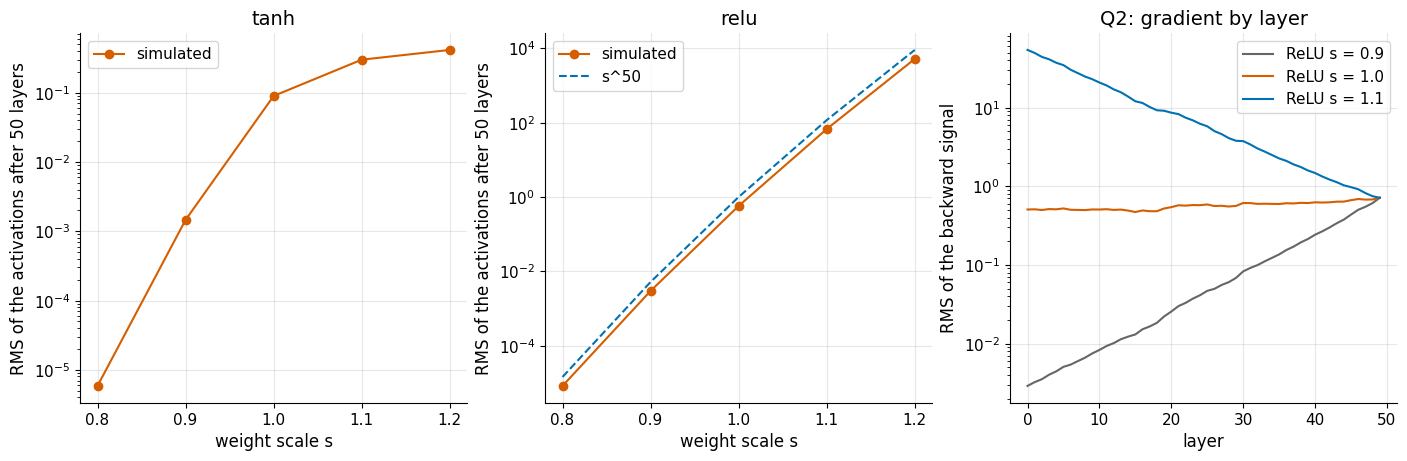

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); sc_list = [0.8, 0.9, 1.0, 1.1, 1.2]
for act, ax in zip(("tanh", "relu"), axes[:2]): ax.semilogy(sc_list, tb1[tb1.activation == act]["RMS of activations after 50 layers"], "o-", color=HIGHLIGHT, label="simulated"); ax.set_xlabel("weight scale s"); ax.set_ylabel("RMS of the activations after 50 layers"); ax.set_title(f"{act}"); ax.legend()
axes[1].semilogy(sc_list, [s ** 50 for s in sc_list], "--", color=MAIN, label="s^50"); axes[1].legend()
for s, colr in [(0.9, NEUTRAL), (1.0, HIGHLIGHT), (1.1, MAIN)]: _, gn, _ = run_net("relu", s); axes[2].semilogy(gn, color=colr, label=f"ReLU s = {s}")
axes[2].set_xlabel("layer"); axes[2].set_ylabel("RMS of the backward signal"); axes[2].legend(); axes[2].set_title("Q2: gradient by layer")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- **tanh:** the RMS of the activations after 50 layers is 0.0000 at $s=0.8$, **0.0015 at 0.9**, **0.090 at 1.0**, 0.300 at 1.1 and 0.415 at 1.2; the gradient RMS at the first layer divided by that at the last layer is 0.0018, 0.109, 0.498 and 1.20 for $s=0.9,1.0,1.1,1.2$. Signal and gradient die away below the right scale; above it they stay alive here but the units drift towards the saturated regime.
- **ReLU:** the RMS after 50 layers is $8\times10^{-6}$ at $s=0.8$, **0.0030 at 0.9**, **0.574 at 1.0 (He)**, **67 at 1.1** and **5,221 at 1.2**. The recursion $0.707\,s^{50}$ predicts $1.0\times10^{-5}$, 0.0036, 0.707, 83 and 6,430: the right exponential rate (all five within 20 %, a constant factor 0.81 from finite width and the fact that real activations are not exactly symmetric).
- A 10 % error in the scale gives a variance factor of $1.1^{100}=1.4\times10^4$ or $0.9^{100}=2.7\times10^{-5}$; the gradient at the first layer follows the same law, by a factor of 76 (ReLU, $s=1.1$) or 0.004 ($s=0.9$) against the last layer. The variance of a pre-activation over 20,000 random weight draws (1.895) matches $\sigma_w^2\|h\|^2$ (1.897).
- **Decision.** Use He initialisation with ReLU and Xavier/LeCun with tanh, and add normalisation or residual connections for networks of more than a few dozen layers; verify an architecture by printing the activation RMS per layer on a random batch before training.

---
### Example 2: MC dropout against deep ensembles (uncertainty on a noisy sine)

**Scenario.** 60 noisy observations $y=\sin(2x)+0.2\varepsilon$ with $x\in[-2,2]$; we want a prediction and an uncertainty at $x\in[-4,4]$. Models: (a) one network trained with dropout 0.2 and queried 200 times with dropout on (MC dropout); (b) an ensemble of 10 networks trained from different seeds without dropout.

**Questions.** (1) Prediction error (RMSE against the true function) inside $[-2,2]$ for each. (2) Predictive standard deviation inside and outside the data range. (3) Share of grid points in $[-2,2]$ where the true function lies within $\pm2$ predictive standard deviations (coverage of the function, not of new noisy data).

In [16]:
g = np.random.default_rng(21); xt = g.uniform(-2, 2, 60)[:, None]; yt = np.sin(2 * xt) + 0.2 * g.normal(size=(60, 1)); xq = np.linspace(-4, 4, 161)[:, None]; ftrue = np.sin(2 * xq[:, 0]); inn = (np.abs(xq[:, 0]) <= 2)
nd = fit_reg(MLP([1, 64, 64, 1], "xavier", seed=1, drop=0.2), xt, yt, epochs=3000, lr=0.01, seed=2); rng = np.random.default_rng(3); mc = np.array([nd.forward(xq, train=True, rng=rng)[:, 0] for _ in range(200)]); mc_m, mc_s = mc.mean(axis=0), mc.std(axis=0)
ens = np.array([fit_reg(MLP([1, 64, 64, 1], "xavier", seed=10 + k), xt, yt, epochs=3000, lr=0.01, seed=k).forward(xq)[:, 0] for k in range(10)]); en_m, en_s = ens.mean(axis=0), ens.std(axis=0, ddof=1)
rm = lambda m: np.sqrt(np.mean((m[inn] - ftrue[inn]) ** 2)); cov = lambda m, s: np.mean(np.abs(m[inn] - ftrue[inn]) <= 2 * s[inn])
tab = pd.DataFrame({"MC dropout": {"RMSE inside": rm(mc_m), "mean std inside": mc_s[inn].mean(), "mean std outside (|x| > 3)": mc_s[np.abs(xq[:, 0]) > 3].mean(), "coverage of the true function (+-2 sd)": cov(mc_m, mc_s)}, "Deep ensemble (10)": {"RMSE inside": rm(en_m), "mean std inside": en_s[inn].mean(), "mean std outside (|x| > 3)": en_s[np.abs(xq[:, 0]) > 3].mean(), "coverage of the true function (+-2 sd)": cov(en_m, en_s)}}); print(tab.round(4).to_string())

                                        MC dropout  Deep ensemble (10)
RMSE inside                                 0.1390              0.1007
mean std inside                             0.2252              0.0350
mean std outside (|x| > 3)                  0.2139              0.1805
coverage of the true function (+-2 sd)      1.0000              0.5185


### 12.5 Asserts

In [17]:
assert tab.loc["RMSE inside"].max() < 0.2 and tab.loc["mean std outside (|x| > 3)", "Deep ensemble (10)"] > 2 * tab.loc["mean std inside", "Deep ensemble (10)"]
print("all checks passed")

all checks passed


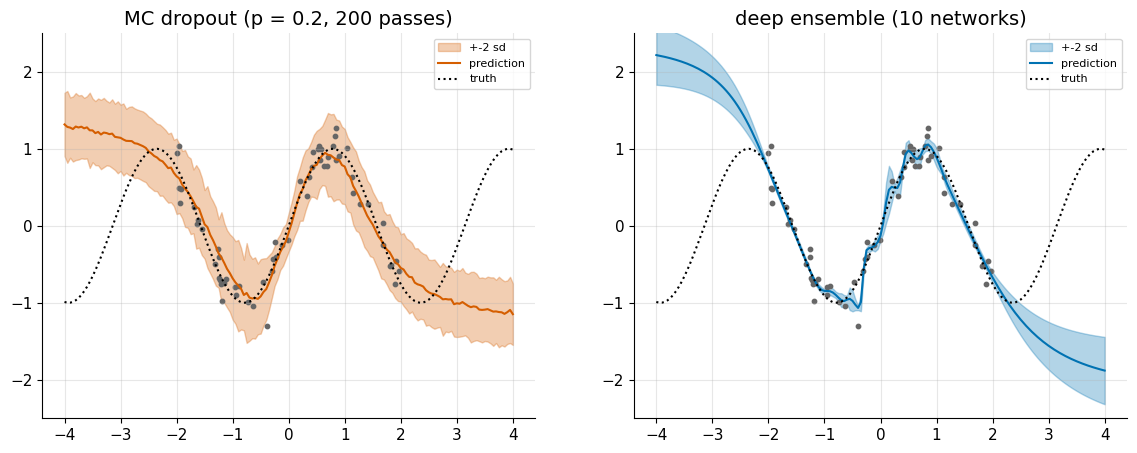

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5));
for ax, (nm, m_, s_, colr) in zip(axes, [("MC dropout (p = 0.2, 200 passes)", mc_m, mc_s, HIGHLIGHT), ("deep ensemble (10 networks)", en_m, en_s, MAIN)]): ax.fill_between(xq[:, 0], m_ - 2 * s_, m_ + 2 * s_, color=colr, alpha=0.3, label="+-2 sd"); ax.plot(xq[:, 0], m_, color=colr, label="prediction"); ax.plot(xq[:, 0], ftrue, color="black", linestyle=":", label="truth"); ax.scatter(xt[:, 0], yt[:, 0], s=10, color=NEUTRAL); ax.set_ylim(-2.5, 2.5); ax.legend(fontsize=8); ax.set_title(nm)
plt.show()

### 12.7 Interpretation and decision (Example 2)
- Inside the data range the **ensemble** of 10 networks is more accurate (RMSE **0.101** against **0.139** for the dropout network, both against the true function) and its disagreement shows what a data-free extrapolation looks like: the predictive standard deviation is **0.035 inside** and **0.181 outside** the data range (5.2 times larger).
- **MC dropout does not detect the extrapolation:** its standard deviation is 0.225 inside and **0.214 outside**. It is about the size of the observation noise (0.2) everywhere, because it reflects the noise injected by dropout, not the distance from the data (the 3D surface of 9.3 shows the same: 0.212 inside and 0.211 outside).
- Coverage of the **true function** by $\pm2$ predictive standard deviations inside the data range is 100 % for MC dropout (intervals too wide, they contain the observation noise) and only **51.9 %** for the ensemble (its spread, 0.035, is far smaller than the function error 0.10 because all members share the same bias).
- **Decision.** Use ensembles (or Gaussian processes, 09_10) when the uncertainty must grow away from the data; use MC dropout as a cheap proxy for the amount of noise a network is sensitive to, not as an out-of-distribution detector.

---
### Example 3: label smoothing on separable data

**Scenario.** 400 two-dimensional points of two well-separated classes are fitted with logistic regression by gradient descent (learning rate 0.5, 2,000 steps). Without smoothing the weights keep growing; with $\varepsilon=0.1$ the optimum is finite. We compare the final logit gap, the average predicted confidence and the expected calibration error on a noisy test set where 8 % of the labels are flipped.

**Questions.** (1) What are the final weight norms and mean confidence with and without smoothing? (2) Compare with the theoretical optimum logit gap $\ln\frac{1-\varepsilon/2}{\varepsilon/2}$. (3) Which model is better calibrated on the noisy test set (log loss, ECE)?

In [19]:
from scipy.special import expit
g = np.random.default_rng(31); n = 400; Xs = np.vstack([g.normal([-2, 0], 0.7, (n // 2, 2)), g.normal([2, 0], 0.7, (n // 2, 2))]); ys = np.r_[np.zeros(n // 2), np.ones(n // 2)]; Xte = np.vstack([g.normal([-2, 0], 0.7, (2000, 2)), g.normal([2, 0], 0.7, (2000, 2))]); yte0 = np.r_[np.zeros(2000), np.ones(2000)]; flip = g.random(4000) < 0.08; yte = np.where(flip, 1 - yte0, yte0)
def train(eps, steps=2000, lr=0.5):
    w = np.zeros(2); b = 0.0; tgt = ys * (1 - eps) + eps / 2; hist = []
    for t in range(steps): q = expit(Xs @ w + b); gr = Xs.T @ (q - tgt) / n; w -= lr * gr; b -= lr * np.mean(q - tgt); hist.append(np.linalg.norm(w))
    return w, b, np.array(hist)
def ece(q, y, bins=10): ix = np.minimum((q * bins).astype(int), bins - 1); return sum(np.mean(ix == k) * abs(y[ix == k].mean() - q[ix == k].mean()) for k in range(bins) if np.any(ix == k))
rows = {}
for eps in (0.0, 0.1):
    w, b, h = train(eps); q = expit(Xte @ w + b); logit_tr = Xs @ w + b; lo = -np.mean(yte * np.log(np.clip(q, 1e-12, 1)) + (1 - yte) * np.log(np.clip(1 - q, 1e-12, 1))); conf = np.mean(np.maximum(q, 1 - q)); rows[eps] = {"weight norm": np.linalg.norm(w), "mean |logit| on training data": np.abs(logit_tr).mean(), "mean confidence (test)": conf, "test accuracy": np.mean((q > 0.5) == yte), "test accuracy vs noisy labels - confidence gap": conf - np.mean((q > 0.5) == yte), "test log loss": lo, "ECE": ece(q, yte)}; rows[eps]["h"] = h
tb3 = pd.DataFrame({k: {a: b_ for a, b_ in v.items() if a != "h"} for k, v in rows.items()}); print(tb3.round(4).to_string()); print(f"Q2: theoretical optimal logit gap for eps = 0.1: ln((1 - eps/2) / (eps/2)) = {np.log(0.95 / 0.05):.4f}; fitted average |logit| at eps = 0.1: {tb3.loc['mean |logit| on training data', 0.1]:.3f} | the noise floor of the test labels: accuracy at most {1 - 0.08:.2f}")

                                                    0.0     0.1
weight norm                                      5.5536  1.5205
mean |logit| on training data                   10.8288  2.9639
mean confidence (test)                           0.9944  0.9279
test accuracy                                    0.9175  0.9180
test accuracy vs noisy labels - confidence gap   0.0769  0.0099
test log loss                                    0.9026  0.3240
ECE                                              0.0785  0.0572
Q2: theoretical optimal logit gap for eps = 0.1: ln((1 - eps/2) / (eps/2)) = 2.9444; fitted average |logit| at eps = 0.1: 2.964 | the noise floor of the test labels: accuracy at most 0.92


### 12.6 Asserts

In [20]:
assert abs(np.log(0.95 / 0.05) - 2.9444) < 1e-3 and tb3.loc["weight norm", 0.0] > tb3.loc["weight norm", 0.1] and tb3.loc["ECE", 0.1] < tb3.loc["ECE", 0.0] and tb3.loc["test log loss", 0.1] < tb3.loc["test log loss", 0.0] and rows[0.0]["h"][-1] > rows[0.0]["h"][1000] > rows[0.0]["h"][100]
print("all checks passed")

all checks passed


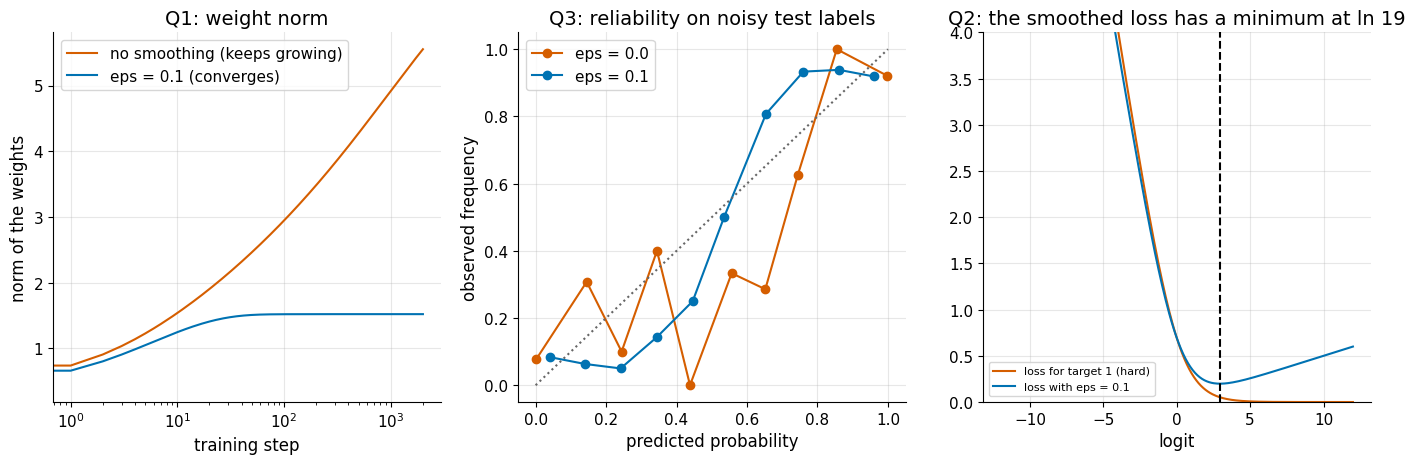

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].plot(rows[0.0]["h"], color=HIGHLIGHT, label="no smoothing (keeps growing)"); axes[0].plot(rows[0.1]["h"], color=MAIN, label="eps = 0.1 (converges)"); axes[0].set_xscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("norm of the weights"); axes[0].legend(); axes[0].set_title("Q1: weight norm")
for eps, colr in [(0.0, HIGHLIGHT), (0.1, MAIN)]:
    w, b, _ = train(eps); q = expit(Xte @ w + b); ix = np.minimum((q * 10).astype(int), 9); axes[1].plot([q[ix == k].mean() for k in range(10) if np.any(ix == k)], [yte[ix == k].mean() for k in range(10) if np.any(ix == k)], "o-", color=colr, label=f"eps = {eps}")
axes[1].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[1].legend(); axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed frequency"); axes[1].set_title("Q3: reliability on noisy test labels")
zz = np.linspace(-12, 12, 300); axes[2].plot(zz, -np.log(expit(zz)), color=HIGHLIGHT, label="loss for target 1 (hard)"); axes[2].plot(zz, -(0.95 * np.log(expit(zz)) + 0.05 * np.log(1 - expit(zz))), color=MAIN, label="loss with eps = 0.1"); axes[2].axvline(np.log(19), color="black", linestyle="--"); axes[2].set_ylim(0, 4); axes[2].legend(fontsize=8); axes[2].set_xlabel("logit"); axes[2].set_title("Q2: the smoothed loss has a minimum at ln 19")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- Without smoothing the weight norm keeps growing (**5.55** after 2,000 steps and still rising: the optimum of the separable problem is at infinity); with $\varepsilon=0.1$ it converges at **1.52**. The mean $|\text{logit}|$ on the training data is **10.83** against **2.96**, almost exactly the theoretical gap $\ln19=2.944$.
- On a test set where 8 % of the labels are flipped (best possible accuracy 92 %), both models have the same accuracy (91.75 % and 91.80 %), but the unsmoothed model claims **99.4 %** confidence (a gap of 7.7 points to its accuracy) against **92.8 %** for the smoothed model (gap 1.0 point). The test log loss falls from **0.903 to 0.324** and the ECE from 0.0785 to 0.0572.
- **Decision.** Label smoothing (about 0.1) is a cheap fix for over-confidence on noisy labels; keep it out of models whose confidence is used for knowledge distillation or ranking, and always check calibration on held-out data.

---
### Example 4: how much does the random seed matter?

**Scenario.** The same network ($1\to32\to32\to1$, no dropout) is trained on the same 60 points from 30 different random seeds (initial weights), and we measure the test error on 500 held-out points. Separately, we train with minibatches of size 4, 16 and 64 (200 epochs of Adam on a 600-point training set) and look at the spread of the final test error.

**Questions.** (1) What are the mean and standard deviation of the test RMSE over the 30 seeds, and how does the spread compare with the difference between "He" and "Xavier" initialisation? (2) How does the spread over seeds depend on the batch size?

In [22]:
g = np.random.default_rng(41); xtr = g.uniform(-2, 2, 60)[:, None]; ytr = np.sin(2 * xtr) + 0.2 * g.normal(size=(60, 1)); xte = g.uniform(-2, 2, 500)[:, None]; yte_ = np.sin(2 * xte) + 0.2 * g.normal(size=(500, 1)); out = {}
for init in ("xavier", "he"): out[init] = np.array([np.sqrt(np.mean((fit_reg(MLP([1, 32, 32, 1], init, seed=s), xtr, ytr, epochs=1500, lr=0.01).forward(xte) - yte_) ** 2)) for s in range(30)])
print(pd.DataFrame({k: {"mean test RMSE": v.mean(), "SD over seeds": v.std(ddof=1), "min": v.min(), "max": v.max()} for k, v in out.items()}).T.round(4).to_string()); diff = out["he"].mean() - out["xavier"].mean(); se = np.sqrt(out["he"].var(ddof=1) / 30 + out["xavier"].var(ddof=1) / 30); print(f"difference He - Xavier: {diff:.4f} +/- {se:.4f} (t = {diff / se:.2f}) | noise floor of the labels (0.2): the RMSE cannot go below it")
xb = g.uniform(-2, 2, 600)[:, None]; yb = np.sin(2 * xb) + 0.2 * g.normal(size=(600, 1)); spread = {}
for B in (4, 16, 64):
    errs = []
    for s in range(12):
        net_ = MLP([1, 32, 32, 1], "xavier", seed=s); rg = np.random.default_rng(100 + s)
        for ep in range(40):
            perm = rg.permutation(600)
            for k in range(0, 600, B): ix = perm[k:k + B]; pr = net_.forward(xb[ix]); net_.adam(net_.backward(2 * (pr - yb[ix]) / len(ix)), 0.005)
        errs.append(np.sqrt(np.mean((net_.forward(xte) - yte_) ** 2)))
    spread[B] = (np.mean(errs), np.std(errs, ddof=1))
print("Q2: minibatch training, test RMSE mean and SD over 12 seeds:", {B: (round(m, 4), round(s, 4)) for B, (m, s) in spread.items()})

        mean test RMSE  SD over seeds     min     max
xavier          0.2259         0.0062  0.2205  0.2568
he              0.2247         0.0032  0.2219  0.2376
difference He - Xavier: -0.0011 +/- 0.0013 (t = -0.87) | noise floor of the labels (0.2): the RMSE cannot go below it


Q2: minibatch training, test RMSE mean and SD over 12 seeds: {4: (np.float64(0.2418), np.float64(0.031)), 16: (np.float64(0.2227), np.float64(0.0108)), 64: (np.float64(0.2223), np.float64(0.0102))}


### 12.7 Asserts

In [23]:
assert out["xavier"].std(ddof=1) > 0 and out["xavier"].mean() < 0.4 and 0.15 < out["he"].mean() < 0.4 and all(0.18 < v[0] < 0.5 for v in spread.values())
print("all checks passed")

all checks passed


C:\Users\Ahmed.MostafaAttia\AppData\Local\Temp\ipykernel_44000\3490924923.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].boxplot([out["xavier"], out["he"]], labels=["Xavier", "He"]); axes[0].scatter(np.r_[np.ones(30), 2 * np.ones(30)], np.r_[out["xavier"], out["he"]], s=10, color=HIGHLIGHT); axes[0].axhline(0.2, color="black", linestyle=":", label="label noise floor"); axes[0].legend(); axes[0].set_ylabel("test RMSE"); axes[0].set_title("Q1: 30 seeds per initialisation")


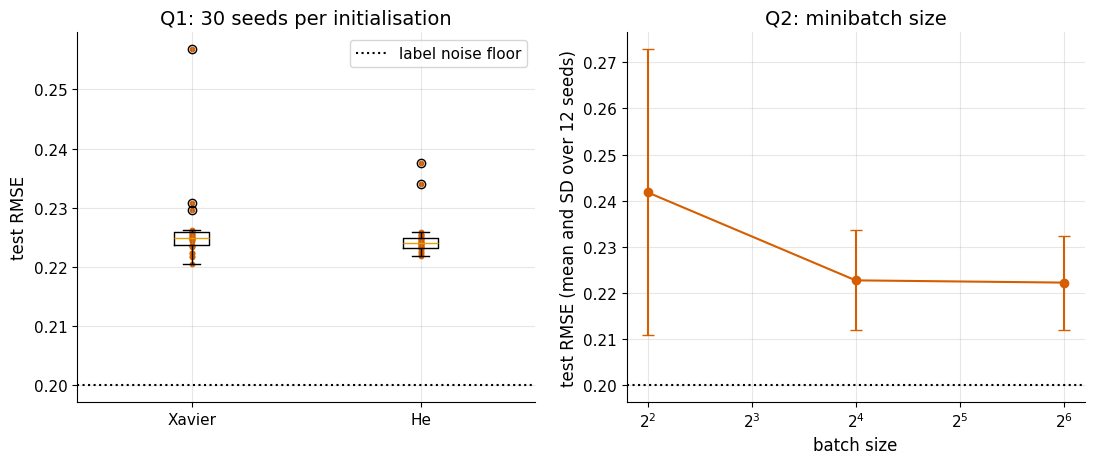

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].boxplot([out["xavier"], out["he"]], labels=["Xavier", "He"]); axes[0].scatter(np.r_[np.ones(30), 2 * np.ones(30)], np.r_[out["xavier"], out["he"]], s=10, color=HIGHLIGHT); axes[0].axhline(0.2, color="black", linestyle=":", label="label noise floor"); axes[0].legend(); axes[0].set_ylabel("test RMSE"); axes[0].set_title("Q1: 30 seeds per initialisation")
axes[1].errorbar(list(spread), [m for m, _ in spread.values()], yerr=[s for _, s in spread.values()], fmt="o-", color=HIGHLIGHT, capsize=4); axes[1].set_xscale("log", base=2); axes[1].axhline(0.2, color="black", linestyle=":"); axes[1].set_xlabel("batch size"); axes[1].set_ylabel("test RMSE (mean and SD over 12 seeds)"); axes[1].set_title("Q2: minibatch size")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- Over 30 seeds the test RMSE is **0.2259 (SD 0.0062) with Xavier and 0.2247 (SD 0.0032) with He** initialisation, with a worst Xavier run at 0.257; the difference between the two is -0.0011 $\pm$ 0.0013 ($t=-0.87$), not significant. The label noise floor is 0.2: both initialisations are within 12 % of the best possible. A reported "improvement" of 0.001 between two single runs would be pure seed noise.
- Minibatch training from 12 seeds: **batch 4 gives a test RMSE of 0.2418 with a seed-to-seed SD of 0.031**, batch 16 gives 0.2227 (SD 0.0108) and batch 64 gives 0.2223 (SD 0.0102): small batches inject more gradient noise and a larger spread.
- **Decision.** Report results as mean $\pm$ SD over several seeds, and treat differences smaller than the seed spread as not demonstrated.

## 13. Where it is used

### Statistics
- **Monte-Carlo and bootstrap thinking** (averaging stochastic passes, ensembles), **random-effects** and **Bayesian neural networks** (priors on weights), variance of stochastic gradient estimators and **stochastic approximation** theory.

### Data science
- **Reproducibility and seeds** in experiments (reporting the mean and spread over seeds, not one run), **uncertainty from ensembles** for decisions, regularisation choices (dropout, weight decay, label smoothing) tuned by cross-validation.

### ML and AI
- **Initialisation recipes** in every framework, **dropout** in transformers and CNNs, **MC dropout and deep ensembles** for uncertainty and out-of-distribution detection, **label smoothing** in image classification and machine translation, **batch-size scaling** and gradient noise in large-scale training, normalisation layers and residual connections as variance controllers.

## 14. Common pitfalls and misconceptions

- **Using one initialisation scale for every activation:** tanh wants $1/n$, ReLU wants $2/n$ (Example 1).
- **Initial scale errors compound exponentially:** 10 % too large over 50 layers is a factor $10^4$ in variance.
- **Forgetting the $1/(1-p)$ scaling** (or dropout at test time): the mean prediction changes by a factor $1-p$.
- **Treating MC-dropout spread as a full uncertainty:** it ignores the noise of the data and is usually too small; compare with an ensemble (Example 2).
- **Reading one training run:** the seed changes the result by a standard deviation that may be larger than the effect of the change under study (Example 4).
- **Label smoothing and calibration:** it reduces over-confidence but can hurt distillation and rank-based confidence; check calibration on held-out data (Example 3).
- **Large batches for free:** the gradient noise falls as $1/\sqrt B$, but the noise also helps generalisation; scale the learning rate with the batch size.
- **Zero initial weights:** every unit in a layer receives the same gradient and stays identical (symmetry); random initialisation breaks it.

## 15. Exercises

1. A layer has 400 inputs. Compute the standard deviation of the He and of the LeCun initial weights, and the Xavier standard deviation for 400 inputs and 100 outputs.
2. A unit has activation 3; with dropout rate 0.5, what are the possible outputs, the mean and the variance?
3. For a 3-class problem with label smoothing 0.1, write the target vector for class 2, and the cross-entropy loss for the prediction $(0.1,0.8,0.1)$.
4. The minibatch gradient has SD 0.4 for $B=16$. Estimate its SD for $B=64$ and $B=1024$ (ignoring the finite-population factor).
5. After 20 layers with weight scale $s=1.05$ times the stable one, by what factor has the signal variance changed? What scale error is tolerable if the variance should stay within a factor 2 after 100 layers?
6. (Harder) Train the network of Example 2 with dropout rates 0.05, 0.2 and 0.4 and report the average predictive standard deviation inside and outside the data range.

Solutions are at the end.

## 16. Summary table

| Topic | Rule | Why |
|---|---|---|
| Variance per layer | $q_l=n\sigma_w^2q_{l-1}$ (tanh/linear) | stay near 1 |
| LeCun / Xavier | $\sigma_w^2=1/n_{\text{in}}$ or $2/(n_{\text{in}}+n_{\text{out}})$ | tanh |
| He | $\sigma_w^2=2/n_{\text{in}}$ | ReLU halves the variance |
| Dropout | mean $h$, variance $h^2p/(1-p)$ | noise, regularisation |
| MC dropout | std over passes | uncertainty (lower bound) |
| Label smoothing | target $(1-\varepsilon)y+\varepsilon/K$ | finite optimal logits |
| Minibatch noise | SD $\propto1/\sqrt B$ | gradient noise |
| Seeds | report mean $\pm$ SD | reproducibility |

## Solutions

In [25]:
print(f"1: He SD {np.sqrt(2 / 400):.4f}, LeCun SD {np.sqrt(1 / 400):.4f}, Xavier SD {np.sqrt(2 / 500):.4f}")
print(f"2: outputs 0 or {3 / 0.5:.1f}; mean {3:.1f}; variance {9 * 0.5 / 0.5:.1f}")
tgt = np.array([0.1 / 3, 1 - 0.1 + 0.1 / 3, 0.1 / 3]); pr = np.array([0.1, 0.8, 0.1]); print(f"3: target {tgt.round(4)}, loss {-np.sum(tgt * np.log(pr)):.4f} (hard target: {-np.log(0.8):.4f})")
print(f"4: SD for B = 64: {0.4 * np.sqrt(16 / 64):.3f}, for B = 1024: {0.4 * np.sqrt(16 / 1024):.3f}")
print(f"5: variance factor after 20 layers with s = 1.05: {1.05 ** 40:.2f}; a factor 2 after 100 layers needs s^200 < 2, i.e. s < {2 ** (1 / 200):.4f} (an error below 0.35%)")
res6 = {}
for r in (0.05, 0.2, 0.4):
    nt = fit_reg(MLP([1, 64, 64, 1], "xavier", seed=5, drop=r), xt, yt, epochs=2000, lr=0.01, seed=6); rg = np.random.default_rng(7); sd_ = np.std([nt.forward(xq, train=True, rng=rg)[:, 0] for _ in range(100)], axis=0); res6[r] = (sd_[inn].mean(), sd_[np.abs(xq[:, 0]) > 3].mean())
print("6: mean predictive std (inside, outside |x| > 3):", {r: (round(a, 4), round(b, 4)) for r, (a, b) in res6.items()})
assert abs(3 / 0.5 - 6) < 1e-12 and res6[0.4][0] > res6[0.05][0]

1: He SD 0.0707, LeCun SD 0.0500, Xavier SD 0.0632
2: outputs 0 or 6.0; mean 3.0; variance 9.0
3: target [0.0333 0.9333 0.0333], loss 0.3618 (hard target: 0.2231)
4: SD for B = 64: 0.200, for B = 1024: 0.050
5: variance factor after 20 layers with s = 1.05: 7.04; a factor 2 after 100 layers needs s^200 < 2, i.e. s < 1.0035 (an error below 0.35%)


6: mean predictive std (inside, outside |x| > 3): {0.05: (np.float64(0.1351), np.float64(0.1843)), 0.2: (np.float64(0.2333), np.float64(0.2491)), 0.4: (np.float64(0.2628), np.float64(0.298))}


**1.** He: $\sqrt{2/400}=$ **0.0707**; LeCun: $\sqrt{1/400}=$ **0.0500**; Xavier with 400 inputs and 100 outputs: $\sqrt{2/500}=$ **0.0632**.

**2.** The output is 0 or $3/0.5=$ **6**, with mean **3** and variance $9\cdot0.5/0.5=$ **9**: the average is unchanged, the spread is as large as the activation.

**3.** The target is $(0.033,0.933,0.033)$ and the cross-entropy of $(0.1,0.8,0.1)$ is **0.362**, against 0.223 for the hard target: smoothing raises the loss of a prediction that is correct but not smooth.

**4.** The SD scales as $1/\sqrt B$: **0.20** for $B=64$ and **0.05** for $B=1024$.

**5.** With $s=1.05$ the variance after 20 layers is multiplied by $1.05^{40}=$ **7.04**; to stay within a factor 2 after 100 layers we need $s^{200}<2$, i.e. $s<$ **1.0035**: the scale must be right to 0.35 %.

**6.** The mean predictive standard deviation (inside, outside the data range) is **(0.135, 0.184)** for dropout 0.05, **(0.233, 0.249)** for 0.2 and **(0.263, 0.298)** for 0.4: it grows with the dropout rate but only slightly outside the data.